# Nashik AQI Forecasting — CNN-LSTM, next 7 days

Four Nashik monitoring stations (CPCB hourly data). For each station a CNN-LSTM reads the
last **24 hours** of seven pollutants (**PM2.5, PM10, NO₂, SO₂, CO, O₃, NH₃**) and predicts
the next hour. Feeding each prediction back in gives a **168-hour (7-day)** forecast, which
is then turned into **7 daily CPCB AQI values** per station.

**Data source:** CPCB Central Control Room repository,
https://airquality.cpcb.gov.in/ccr/#/repository/data (State: Maharashtra, City: Nashik,
stations Gangapur Road, MIDC Ambad, Hirawadi and Pandav Nagari, all MPCB; frequency 1H).

**Data files** (one per station, hourly, 2017-01-01 → 2026-09-30):
`gangapur_road_nashik.csv`, `midc_ambad_nashik.csv`, `hirwadi_nashik.csv`,
`pandav_nagari_nashik.csv`. Each joins the station's earlier CPCB export with the 2026 file
downloaded from the repository on 19 Oct 2026 (Pandav Nagari: 2025 and 2026 files), keeping
the CPCB columns unchanged. Where the two sources overlap, every value is identical. The
latest CPCB data ended on 30 Sep 2026, so the forecasts cover 1–7 October 2026.

Run the cells top to bottom. In Colab, cell 1 asks you to upload the four CSV files.

In [1]:
# Cell 0 — Imports and settings
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

DATA_DIR = "data"
OUTPUT_DIR = "outputs_7day"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

POLLUTANTS = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3"]
LOOKBACK = 24        # hours of history the model sees
HORIZON = 168        # hours to forecast (7 days)
TEST_DAYS = 28       # last 4 weeks of each station: held out for testing
VAL_DAYS = 56        # 8 weeks before that: used for early stopping
print("TensorFlow", tf.__version__)

TensorFlow 2.19.0


## 1. Load the four station files
The file name decides the station. Timestamps are read with their exact format
(`2026-01-01 00:00:00`); the notebook stops if more than 1% of them cannot be read.

In [2]:
# Cell 1 — Upload (Colab only) and load
def csv_files():
    return sorted(p for p in glob.glob(os.path.join(DATA_DIR, "*")) if p.lower().endswith(".csv"))

for path in glob.glob("*.csv") + glob.glob("*.CSV"):   # files dropped into the Colab Files panel
    os.replace(path, os.path.join(DATA_DIR, path))

if not csv_files():
    from google.colab import files
    print("Select the four station CSV files.")
    for name, content in files.upload().items():
        with open(os.path.join(DATA_DIR, name), "wb") as f:
            f.write(content)

STATIONS = {"gangapur": "Gangapur Road", "midcambad": "MIDC Ambad",
            "hirwadi": "Hirwadi", "pandav": "Pandav Nagari"}
COLUMNS = {"PM2.5 (µg/m³)": "PM2.5", "PM10 (µg/m³)": "PM10", "NO2 (µg/m³)": "NO2",
           "SO2 (µg/m³)": "SO2", "CO (mg/m³)": "CO", "Ozone (µg/m³)": "O3",
           "NH3 (µg/m³)": "NH3"}

raw = {}
for path in csv_files():
    key = os.path.basename(path).lower().replace("_", "")
    station = next((s for k, s in STATIONS.items() if k in key), None)
    if station is None:
        print("Skipping (unknown station):", os.path.basename(path))
        continue
    if station in raw:
        raise ValueError(f"Two files for {station}; keep one file per station in {DATA_DIR}/")
    df = pd.read_csv(path)
    missing_cols = [c for c in ["Timestamp", *COLUMNS] if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{path}: missing columns {missing_cols}")
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
    bad = df["Timestamp"].isna().mean()
    if bad > 0.01:
        raise ValueError(f"{path}: {bad:.1%} of timestamps could not be read")
    df = df.rename(columns=COLUMNS)[["Timestamp", *POLLUTANTS]].dropna(subset=["Timestamp"])
    df = df.drop_duplicates("Timestamp").sort_values("Timestamp").set_index("Timestamp")
    raw[station] = df.apply(pd.to_numeric, errors="coerce")
    print(f"{station:14s} {os.path.basename(path):28s} {df.index.min()} → {df.index.max()}  rows={len(df)}")

if sorted(raw) != sorted(STATIONS.values()):
    raise FileNotFoundError(f"Expected 4 stations, found {sorted(raw)}")

Gangapur Road  gangapur_road_nashik.csv     2017-01-01 00:00:00 → 2026-09-30 23:00:00  rows=82488
Hirwadi        hirwadi_nashik.csv           2017-01-01 00:00:00 → 2026-09-30 23:00:00  rows=41616
MIDC Ambad     midc_ambad_nashik.csv        2017-01-01 00:00:00 → 2026-09-30 23:00:00  rows=41616
Pandav Nagari  pandav_nagari_nashik.csv     2017-01-01 00:00:00 → 2026-09-30 23:00:00  rows=41616


## 2. Clean the data and put it on an hourly grid
Sensor faults are set to missing:
- negative values, and PM values of 999 or more (analyser limit);
- the same value repeated for 12 hours or more (stuck sensor);
- CO of exactly 0 (analyser switched off);
- a day whose values barely move (10th–90th percentile spread under 5% of the median):
  a failed sensor jittering around one level.

Each station is then put on a complete hourly grid from its first to its last real
measurement. Absent hours become empty rows; nothing is invented here.

In [3]:
# Cell 2 — Cleaning and hourly grid
def clean(df):
    df = df.copy()
    for p in POLLUTANTS:
        x = df[p]
        bad = x < 0
        if p in ("PM2.5", "PM10"):
            bad |= x >= 999
        run_length = x.groupby((x != x.shift()).cumsum()).transform("size")
        bad |= (run_length >= 12) & x.notna()
        if p == "CO":
            bad |= x == 0
        x = x.mask(bad)
        day = x.groupby(x.index.floor("D"))
        spread = day.transform("quantile", 0.9) - day.transform("quantile", 0.1)
        flat = (day.transform("count") >= 12) & (spread < 0.05 * day.transform("median"))
        df[p] = x.mask(flat)
    measured = df[POLLUTANTS].notna().any(axis=1)
    first, last = df.index[measured].min(), df.index[measured].max()
    return df[POLLUTANTS].resample("h").mean().loc[first:last]

data = {s: clean(df) for s, df in raw.items()}

coverage = pd.DataFrame({
    s: {"first measurement": d.index.min(), "last measurement": d.index.max(),
        "hours": len(d), **{f"{p} missing %": round(100 * d[p].isna().mean(), 1) for p in POLLUTANTS}}
    for s, d in data.items()}).T
coverage

,first measurement,last measurement,hours,PM2.5 missing %,PM10 missing %,NO2 missing %,SO2 missing %,CO missing %,O3 missing %,NH3 missing %
Gangapur Road,2017-01-01 00:00:00,2026-09-30 23:00:00,85440,14.7,14.7,34.5,12.8,23.3,20.2,35.8
Hirwadi,2023-05-23 16:00:00,2026-09-30 23:00:00,29432,7.7,7.8,9.3,10.7,16.0,7.5,9.0
MIDC Ambad,2023-06-14 14:00:00,2026-09-30 23:00:00,28906,7.1,7.2,7.8,7.5,18.1,6.9,8.7
Pandav Nagari,2023-05-22 17:00:00,2026-09-30 18:00:00,29450,4.7,4.5,4.3,4.8,12.9,4.2,5.8


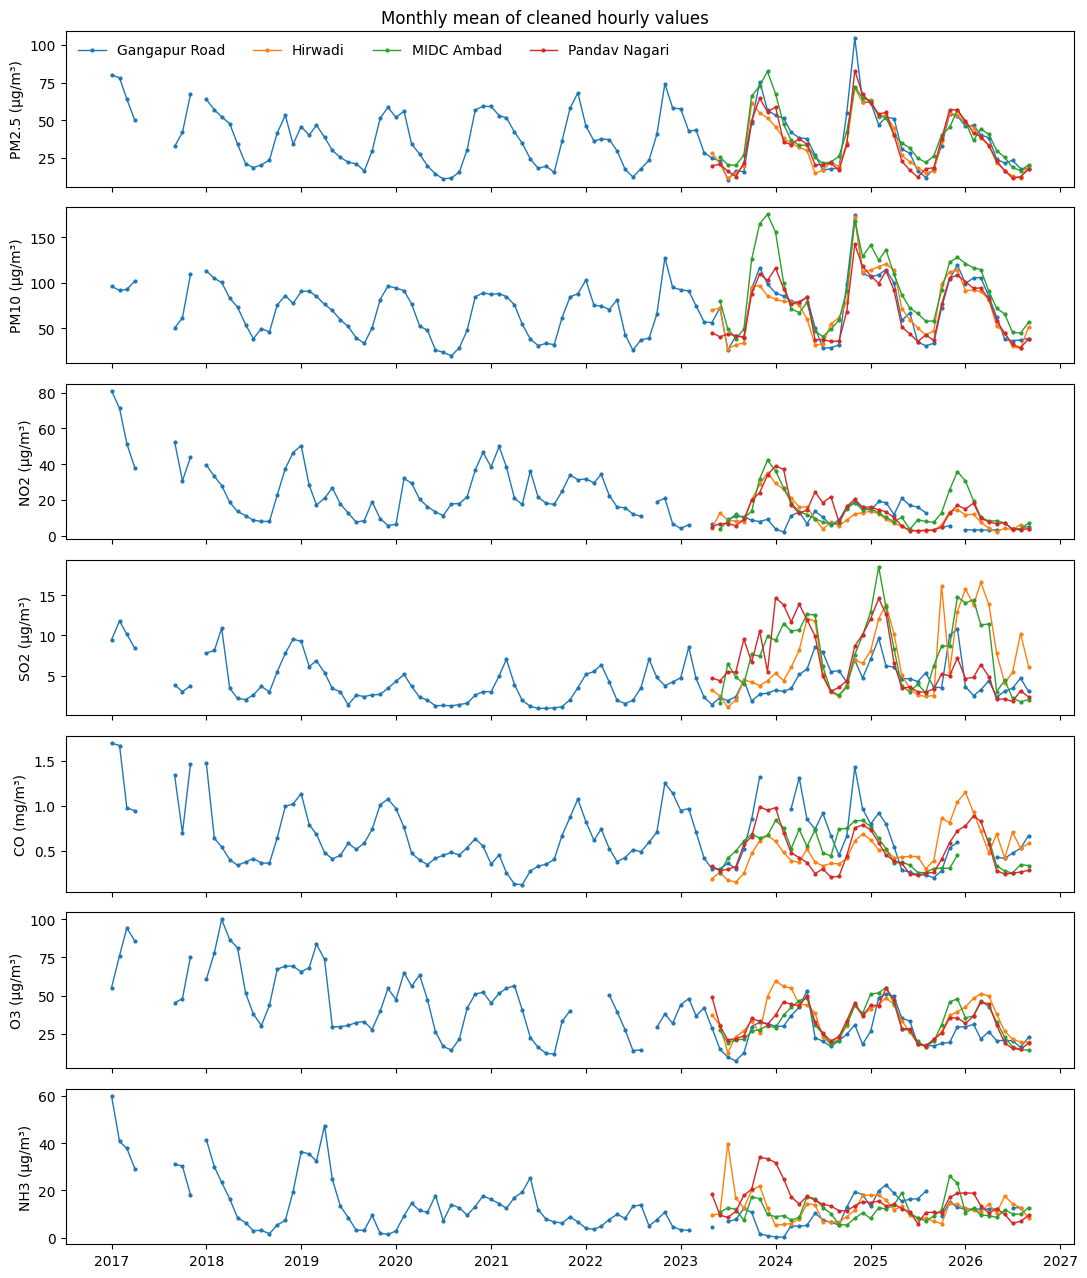

In [4]:
# Cell 3 — Look at the data: monthly averages per station
fig, axes = plt.subplots(len(POLLUTANTS), 1, figsize=(11, 13), sharex=True)
for ax, p in zip(axes, POLLUTANTS):
    for s, d in data.items():
        monthly = d[p].resample("MS").mean()
        ax.plot(monthly.index, monthly.values, marker="o", ms=2, lw=1, label=s)
    ax.set_ylabel(p + (" (mg/m³)" if p == "CO" else " (µg/m³)"))
axes[0].legend(ncol=4, frameon=False)
fig.suptitle("Monthly mean of cleaned hourly values")
fig.tight_layout()
plt.show()

## 3. Split, scale and fill gaps (per station)
- **Split by time**: test = last 28 days, validation = the 56 days before, training = the rest.
- **Scale**: each pollutant is standardised (mean 0, std 1) using the *training* rows only.
- **Fill gaps**: a KNN imputer, also fitted on training rows only, fills missing inputs from
  the other pollutants measured in the same hour. Filled values are only used as model
  *inputs*; they are never used as answers the model is trained or scored on.
- **Time features**: sine/cosine of hour of day and day of year.

In [5]:
# Cell 4 — Preprocessing
TIME_FEATURES = ["hour_sin", "hour_cos", "doy_sin", "doy_cos"]
FEATURES = POLLUTANTS + TIME_FEATURES

def time_features(index):
    h, d = index.hour.to_numpy(), index.dayofyear.to_numpy()
    return np.column_stack([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                            np.sin(2 * np.pi * d / 365.25), np.cos(2 * np.pi * d / 365.25)])

prep = {}
for s, d in data.items():
    test_start = d.index[-1] - pd.Timedelta(days=TEST_DAYS) + pd.Timedelta(hours=1)
    val_start = test_start - pd.Timedelta(days=VAL_DAYS)
    split = np.where(d.index >= test_start, "test", np.where(d.index >= val_start, "val", "train"))

    scaler = StandardScaler().fit(d[split == "train"])
    scaled = scaler.transform(d)
    imputer = KNNImputer(n_neighbors=5, weights="distance").fit(scaled[split == "train"])
    with np.errstate(all="ignore"):   # harmless BLAS warnings on macOS
        filled = imputer.transform(scaled)

    inputs = pd.DataFrame(np.column_stack([filled, time_features(d.index)]),
                          index=d.index, columns=FEATURES).astype("float32")
    prep[s] = {"inputs": inputs, "split": split, "mean": scaler.mean_, "std": scaler.scale_,
               "test_start": test_start}
    print(f"{s:14s} train until {val_start - pd.Timedelta(hours=1)}, test from {test_start}")

Gangapur Road  train until 2026-07-08 23:00:00, test from 2026-09-03 00:00:00


Hirwadi        train until 2026-07-08 23:00:00, test from 2026-09-03 00:00:00


MIDC Ambad     train until 2026-07-08 23:00:00, test from 2026-09-03 00:00:00


Pandav Nagari  train until 2026-07-08 18:00:00, test from 2026-09-02 19:00:00


## 4. Build training sequences
Input: 24 consecutive hours × 11 features. Target: how much each pollutant **changes** in
the next hour (in scaled units). A sequence is used only if at least one pollutant was
really measured at the target hour and at most half of its input values were filled in.
Pollutants not measured at the target hour are left empty and ignored by the loss.

In [6]:
# Cell 5 — Sequences
def make_sequences(s):
    p, d = prep[s], data[s]
    X_all = p["inputs"].to_numpy()
    measured = d[POLLUTANTS].notna().to_numpy()
    target = (d[POLLUTANTS].to_numpy() - p["mean"]) / p["std"]       # NaN where not measured
    X, y, times, split = [], [], [], []
    for t in range(LOOKBACK, len(d)):
        if not measured[t].any() or (~measured[t - LOOKBACK:t]).mean() > 0.5:
            continue
        window = X_all[t - LOOKBACK:t]
        X.append(window)
        y.append(target[t] - window[-1, :len(POLLUTANTS)])            # next-hour change
        times.append(d.index[t])
        split.append(p["split"][t])
    return np.array(X), np.array(y, dtype="float32"), pd.DatetimeIndex(times), np.array(split)

sequences = {s: make_sequences(s) for s in data}
pd.DataFrame({s: pd.Series(sp).value_counts() for s, (_, _, _, sp) in sequences.items()}).T

,train,val,test
Gangapur Road,72121,1071,555
Hirwadi,25564,1078,600
MIDC Ambad,24893,1129,646
Pandav Nagari,26373,1199,608


## 5. CNN-LSTM model and training
Two 1-D convolutions pick up short patterns in the 24 hours, max-pooling halves the
sequence, an LSTM summarises it, and a dense layer outputs the 7 next-hour changes. The
loss is mean squared error over the pollutants that were actually measured. Training stops
when the validation loss has not improved for 8 epochs.

Gangapur Road  epochs=26  best val loss=0.3721


Hirwadi        epochs=15  best val loss=0.2604


MIDC Ambad     epochs=31  best val loss=0.0345


Pandav Nagari  epochs=24  best val loss=0.0255


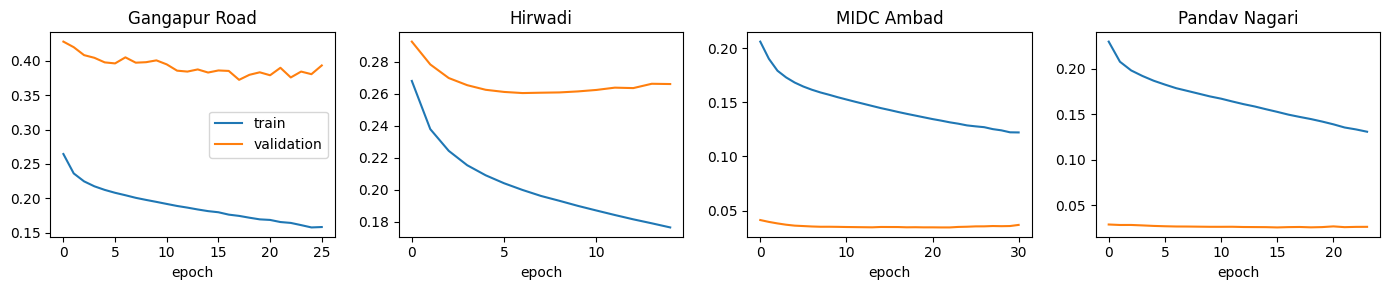

In [7]:
# Cell 6 — Model and training (one model per station)
def masked_mse(y_true, y_pred):
    mask = tf.math.is_finite(y_true)
    err = tf.where(mask, y_true - y_pred, 0.0)
    return tf.reduce_sum(err ** 2) / tf.maximum(tf.reduce_sum(tf.cast(mask, tf.float32)), 1.0)

def build_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(FEATURES))),
        tf.keras.layers.Conv1D(64, 3, activation="relu", padding="causal"),
        tf.keras.layers.Conv1D(32, 3, activation="relu", padding="causal"),
        tf.keras.layers.MaxPooling1D(2),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(len(POLLUTANTS)),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss=masked_mse)
    return model

models, histories = {}, {}
for s, (X, y, _, split) in sequences.items():
    tf.keras.utils.set_random_seed(42)
    model = build_model()
    hist = model.fit(X[split == "train"], y[split == "train"],
                     validation_data=(X[split == "val"], y[split == "val"]),
                     epochs=60, batch_size=128, verbose=0,
                     callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    models[s], histories[s] = model, hist.history
    print(f"{s:14s} epochs={len(hist.history['loss'])}  best val loss={min(hist.history['val_loss']):.4f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (s, h) in zip(axes, histories.items()):
    ax.plot(h["loss"], label="train")
    ax.plot(h["val_loss"], label="validation")
    ax.set_title(s)
    ax.set_xlabel("epoch")
axes[0].legend()
fig.tight_layout()
plt.show()

## 6. The 7-day forecast function
Start from the 24 hours ending at the chosen hour. Then, 168 times: predict the change,
add it to the current level (in µg/m³ or mg/m³, never below 0), turn the new levels back
into scaled inputs, append them with that hour's time features, and drop the oldest hour.
Only the starting 24 hours are real data; everything after is the model's own output.

In [8]:
# Cell 7 — Recursive forecast
def forecast_7_days(s, last_hour):
    p, model = prep[s], models[s]
    window = p["inputs"].loc[last_hour - pd.Timedelta(hours=LOOKBACK - 1):last_hour].to_numpy().copy()
    assert len(window) == LOOKBACK
    level = window[-1, :len(POLLUTANTS)] * p["std"] + p["mean"]          # real units
    hours = pd.date_range(last_hour + pd.Timedelta(hours=1), periods=HORIZON, freq="h")
    out = []
    for i, ts in enumerate(hours):
        change = model(window[None], training=False).numpy()[0] * p["std"]
        level = np.maximum(level + change, 0)
        next_row = np.concatenate([(level - p["mean"]) / p["std"], time_features(hours[i:i + 1])[0]])
        window = np.vstack([window[1:], next_row])
        out.append(level)
    return pd.DataFrame(out, index=hours, columns=POLLUTANTS)

## 7. CPCB daily AQI
CPCB National AQI rules: 24-hour average for PM2.5, PM10, NO₂, SO₂ and NH₃; the highest
8-hour average of the day for CO and O₃. Each pollutant gets a sub-index from the CPCB
breakpoints (straight-line between breakpoints, max 500). The AQI is the highest
sub-index, and is only valid with at least 3 pollutants, one of them PM2.5 or PM10.
Units: µg/m³, CO in mg/m³.

In [9]:
# Cell 8 — AQI functions
AQI_LEVELS = [0, 50, 100, 200, 300, 400, 500]
# Concentration at each AQI level above. CPCB gives no upper limit for "Severe", so the last
# value extends the "Very Poor" band by its own width (AQI is capped at 500 anyway).
BREAKPOINTS = {
    "PM2.5": [0, 30, 60, 90, 120, 250, 380],
    "PM10":  [0, 50, 100, 250, 350, 430, 510],
    "NO2":   [0, 40, 80, 180, 280, 400, 520],
    "SO2":   [0, 40, 80, 380, 800, 1600, 2400],
    "NH3":   [0, 200, 400, 800, 1200, 1800, 2400],
    "CO":    [0, 1.0, 2.0, 10, 17, 34, 51],
    "O3":    [0, 50, 100, 168, 208, 748, 1288],
}
CATEGORIES = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

def aqi_category(aqi):
    for limit, name in zip(AQI_LEVELS[1:], CATEGORIES):
        if aqi <= limit:
            return name
    return "Severe"

def daily_aqi(hourly, use_pollutants=POLLUTANTS):
    """One AQI per 24-hour block of `hourly` (the first block starts at its first row)."""
    block = (hourly.index - hourly.index[0]) // pd.Timedelta(days=1)
    rows = []
    for b, day in hourly.groupby(block):
        sub = {}
        for p in use_pollutants:
            if p in ("CO", "O3"):
                conc = day[p].rolling(8, min_periods=6).mean().max()
            else:
                conc = day[p].mean() if day[p].notna().sum() >= 16 else np.nan
            if np.isfinite(conc):
                sub[p] = min(np.interp(conc, BREAKPOINTS[p], AQI_LEVELS), 500)
        valid = len(sub) >= 3 and ("PM2.5" in sub or "PM10" in sub)
        aqi = max(sub.values()) if valid else np.nan
        rows.append({"day": b + 1, "start": day.index[0], "end": day.index[-1],
                     "AQI": aqi, "category": aqi_category(aqi) if valid else "Not enough data",
                     "main pollutant": max(sub, key=sub.get) if valid else None,
                     **{f"{p} sub-index": sub.get(p, np.nan) for p in POLLUTANTS}})
    return pd.DataFrame(rows)

# Quick check against CPCB band edges: PM2.5 = 60 µg/m³ is AQI 100, PM10 = 250 is AQI 200.
assert np.interp(60, BREAKPOINTS["PM2.5"], AQI_LEVELS) == 100
assert np.interp(250, BREAKPOINTS["PM10"], AQI_LEVELS) == 200

## 8. Test on held-out data
For each station, four 7-day forecasts are made inside its test period (starting on test
days 1, 8, 15 and 22) and compared with what was actually measured. Two simple baselines
are scored on the same hours:
- **persistence**: the last measured value, held for 7 days;
- **climatology**: the training-period average for that month and hour of day.

The table shows the error (RMSE) averaged over the four forecasts. Lower is better.

In [10]:
# Cell 9 — 7-day backtest
def rmse(actual, pred):
    ok = np.isfinite(actual) & np.isfinite(pred)
    return np.sqrt(np.mean((actual[ok] - pred[ok]) ** 2)) if ok.any() else np.nan

rows, aqi_rows = [], []
for s, d in data.items():
    train = d[prep[s]["split"] == "train"]
    climate = train.groupby([train.index.month, train.index.hour]).mean()
    for week in range(4):
        start = prep[s]["test_start"] - pd.Timedelta(hours=1) + pd.Timedelta(days=7 * week)
        pred = forecast_7_days(s, start)
        actual = d.reindex(pred.index)
        last_value = d.loc[:start].ffill().iloc[-1]
        clim = climate.reindex(list(zip(pred.index.month, pred.index.hour))).set_axis(pred.index)
        for p in POLLUTANTS:
            rows.append({"station": s, "pollutant": p,
                         "CNN-LSTM": rmse(actual[p].values, pred[p].values),
                         "persistence": rmse(actual[p].values, np.full(HORIZON, last_value[p])),
                         "climatology": rmse(actual[p].values, clim[p].values)})
        both = pd.DataFrame({"forecast": daily_aqi(pred)["AQI"], "measured": daily_aqi(actual)["AQI"],
                             "station": s}).dropna()
        aqi_rows.append(both)

backtest = pd.DataFrame(rows).groupby(["station", "pollutant"]).mean()
backtest["model best?"] = backtest["CNN-LSTM"] < backtest[["persistence", "climatology"]].min(axis=1)
print(f"CNN-LSTM has the lowest error in {backtest['model best?'].sum()} of {len(backtest)} "
      "station-pollutant pairs")
display(backtest.round(2))

aqi_test = pd.concat(aqi_rows)
aqi_test["error"] = (aqi_test["forecast"] - aqi_test["measured"]).abs()
aqi_test["same category"] = [aqi_category(a) == aqi_category(b)
                             for a, b in zip(aqi_test["forecast"], aqi_test["measured"])]
print("Daily AQI on test days (forecast vs AQI from the measurements):")
aqi_test.groupby("station")[["error", "same category"]].mean().round(2).rename(
    columns={"error": "mean AQI error", "same category": "share same category"})

CNN-LSTM has the lowest error in 1 of 28 station-pollutant pairs


CNN-LSTM  persistence  climatology  model best?
station       pollutant                                                 
Gangapur Road CO             1.17         0.67         0.59        False
              NH3             NaN          NaN          NaN        False
              NO2            5.51         2.49         7.38        False
              O3            73.13        11.36        12.51        False
              PM10          66.14        30.07        24.70        False
              PM2.5         17.98        11.75        11.09        False
              SO2            6.36         3.25         3.28        False
Hirwadi       CO             0.33         0.27         0.33        False
              NH3           18.44         4.52         3.46        False
              NO2            5.41         3.42         4.20        False
              O3            14.90        14.20        10.60        False
              PM10          71.21        34.63        25.25        False
              PM2.5         20.35         8.43        10.10        False
              SO2           13.83        12.91         7.95        False
MIDC Ambad    CO             0.41         0.08         0.22        False
              NH3            4.80         3.50         6.36        False
              NO2            4.97         3.84         3.86        False
              O3             8.79         9.19         9.61         True
              PM10          39.87        26.17        23.96        False
              PM2.5         16.97         8.99        10.58        False
              SO2            6.81         2.16         2.75        False
Pandav Nagari CO             0.30         0.11         0.11        False
              NH3            8.32        17.53         6.79        False
              NO2            5.06         1.60         3.37        False
              O3            21.71        13.23        14.43        False
              PM10          67.16        41.28        21.42        False
              PM2.5         47.96        12.34        10.72        False
              SO2            6.07         1.59         3.33        False

Daily AQI on test days (forecast vs AQI from the measurements):


,mean AQI error,share same category
station,,
Gangapur Road,70.72,0.20
Hirwadi,49.58,0.38
MIDC Ambad,30.98,0.50
Pandav Nagari,79.43,0.24


## 9. Forecast the next 7 days for every station
Each station's forecast starts the hour after its own last measurement, so the dates
differ between stations. If a pollutant was measured in fewer than half of the last 24
hours, its sensor is treated as not working: it is still forecast, but it is **left out of
the AQI**, because its forecast would rest on filled-in values only.

In [11]:
# Cell 10 — Final 7-day forecasts and daily AQI
hourly_rows, daily_rows, summary = [], [], []
for s, d in data.items():
    last = d.index[-1]
    recent = d.loc[last - pd.Timedelta(hours=23):last].notna().mean()
    working = [p for p in POLLUTANTS if recent[p] >= 0.5]
    fc = forecast_7_days(s, last)
    hourly_rows.append(fc.rename_axis("timestamp").reset_index().assign(
        station=s, last_measurement=last, hour_ahead=np.arange(1, HORIZON + 1), type="predicted"))
    daily = daily_aqi(fc, use_pollutants=working)
    daily_rows.append(daily.assign(station=s, last_measurement=last, type="predicted",
                                   pollutants_used=", ".join(working)))
    summary.append({"station": s, "last measurement": last, "forecast from": fc.index[0],
                    "forecast to": fc.index[-1],
                    "left out of AQI": ", ".join(sorted(set(POLLUTANTS) - set(working))) or "none"})

hourly_forecast = pd.concat(hourly_rows, ignore_index=True)
daily_forecast = pd.concat(daily_rows, ignore_index=True)
display(pd.DataFrame(summary).set_index("station"))
daily_forecast[["station", "day", "start", "end", "AQI", "category", "main pollutant"]].round(1)

,last measurement,forecast from,forecast to,left out of AQI
station,,,,
Gangapur Road,2026-09-30 23:00:00,2026-10-01 00:00:00,2026-10-07 23:00:00,NH3
Hirwadi,2026-09-30 23:00:00,2026-10-01 00:00:00,2026-10-07 23:00:00,none
MIDC Ambad,2026-09-30 23:00:00,2026-10-01 00:00:00,2026-10-07 23:00:00,none
Pandav Nagari,2026-09-30 18:00:00,2026-09-30 19:00:00,2026-10-07 18:00:00,none


,station,day,start,end,AQI,category,main pollutant
0,Gangapur Road,1,2026-10-01 00:00:00,2026-10-01 23:00:00,70.8,Satisfactory,CO
1,Gangapur Road,2,2026-10-02 00:00:00,2026-10-02 23:00:00,92.7,Satisfactory,O3
2,Gangapur Road,3,2026-10-03 00:00:00,2026-10-03 23:00:00,151.8,Moderate,O3
3,Gangapur Road,4,2026-10-04 00:00:00,2026-10-04 23:00:00,180.8,Moderate,O3
4,Gangapur Road,5,2026-10-05 00:00:00,2026-10-05 23:00:00,211.7,Poor,O3
5,Gangapur Road,6,2026-10-06 00:00:00,2026-10-06 23:00:00,206.3,Poor,O3
6,Gangapur Road,7,2026-10-07 00:00:00,2026-10-07 23:00:00,129.0,Moderate,O3
7,Hirwadi,1,2026-10-01 00:00:00,2026-10-01 23:00:00,74.7,Satisfactory,PM10
8,Hirwadi,2,2026-10-02 00:00:00,2026-10-02 23:00:00,103.4,Moderate,PM10
9,Hirwadi,3,2026-10-03 00:00:00,2026-10-03 23:00:00,112.4,Moderate,PM10


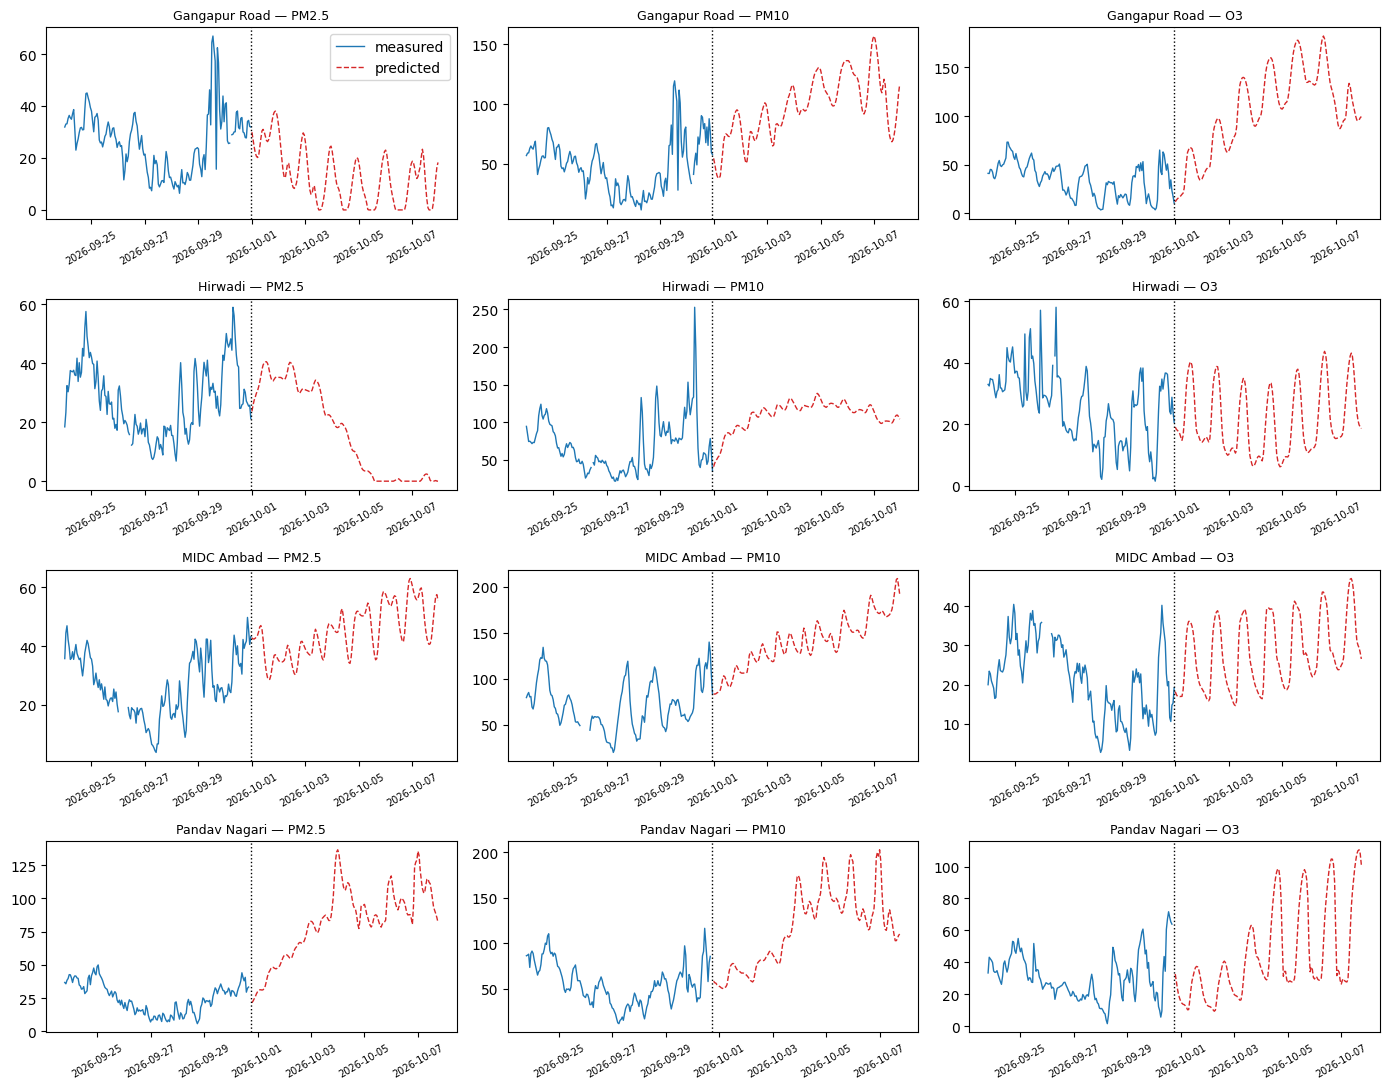

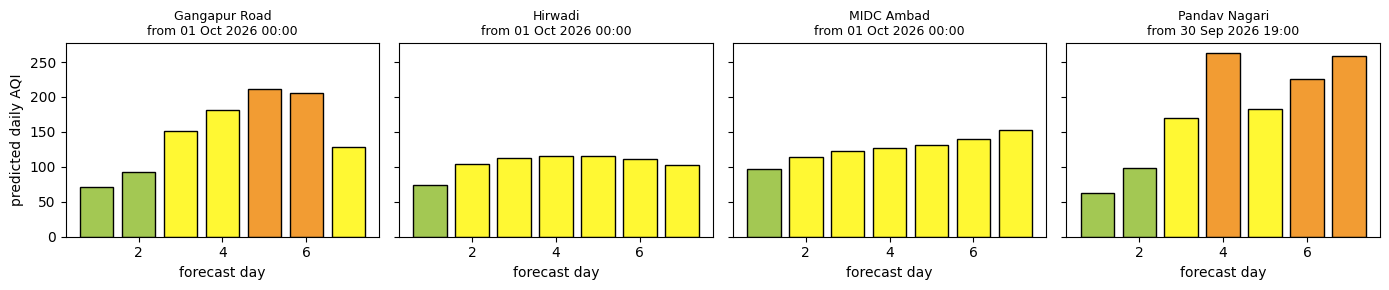

In [12]:
# Cell 11 — Plots: last 7 days measured (solid) and next 7 days predicted (dashed)
SHOW = ["PM2.5", "PM10", "O3"]
fig, axes = plt.subplots(4, len(SHOW), figsize=(14, 11))
for r, (s, d) in enumerate(data.items()):
    fc = hourly_forecast[hourly_forecast.station == s].set_index("timestamp")
    past = d.iloc[-HORIZON:]
    for c, p in enumerate(SHOW):
        ax = axes[r, c]
        ax.plot(past.index, past[p], color="tab:blue", lw=1, label="measured")
        ax.plot(fc.index, fc[p], color="tab:red", lw=1, ls="--", label="predicted")
        ax.axvline(d.index[-1], color="black", ls=":", lw=1)
        ax.set_title(f"{s} — {p}", fontsize=9)
        ax.tick_params(axis="x", labelsize=7, labelrotation=30)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

colors = {"Good": "#009865", "Satisfactory": "#a3c853", "Moderate": "#fff833", "Poor": "#f29c33",
          "Very Poor": "#e93f33", "Severe": "#af2d24", "Not enough data": "lightgrey"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (s, g) in zip(axes, daily_forecast.groupby("station", sort=False)):
    ax.bar(g["day"], g["AQI"], color=[colors[c] for c in g["category"]], edgecolor="black")
    ax.set_title(f"{s}\nfrom {g['start'].iloc[0]:%d %b %Y %H:%M}", fontsize=9)
    ax.set_xlabel("forecast day")
axes[0].set_ylabel("predicted daily AQI")
fig.tight_layout()
plt.show()

## 10. Save the results and check them
The checks re-read the saved files and stop the notebook if anything is wrong.

In [13]:
# Cell 12 — Save and verify
hourly_path = os.path.join(OUTPUT_DIR, "recursive_forecast_7day_hourly.csv")
daily_path = os.path.join(OUTPUT_DIR, "recursive_forecast_7day_daily_aqi.csv")
hourly_forecast[["station", "last_measurement", "timestamp", "hour_ahead", "type", *POLLUTANTS]].round(3) \
    .to_csv(hourly_path, index=False)
daily_forecast[["station", "last_measurement", "day", "start", "end", "type", "AQI", "category",
                "main pollutant", "pollutants_used", *[f"{p} sub-index" for p in POLLUTANTS]]].round(2) \
    .to_csv(daily_path, index=False)

h = pd.read_csv(hourly_path, parse_dates=["timestamp", "last_measurement"])
dd = pd.read_csv(daily_path, parse_dates=["start", "last_measurement"])
assert sorted(h.station.unique()) == sorted(STATIONS.values()), "a station is missing"
assert len(h) == 4 * 168 and (h.groupby("station").size() == 168).all()
assert len(dd) == 4 * 7 and (dd.groupby("station").size() == 7).all()
for s, g in h.groupby("station"):
    expected = pd.date_range(g.last_measurement.iloc[0] + pd.Timedelta(hours=1), periods=168, freq="h")
    assert (pd.DatetimeIndex(g.timestamp) == expected).all(), f"{s}: wrong forecast hours"
assert np.isfinite(h[POLLUTANTS].to_numpy()).all() and (h[POLLUTANTS] >= 0).all().all()
assert dd["AQI"].between(0, 500).all(), "every forecast day needs a valid AQI"
assert (dd["category"] == dd["AQI"].apply(aqi_category)).all()
print("All checks passed:", len(h), "hourly rows,", len(dd), "daily rows")
print("Saved:", hourly_path, "and", daily_path)

All checks passed: 672 hourly rows, 28 daily rows
Saved: outputs_7day/recursive_forecast_7day_hourly.csv and outputs_7day/recursive_forecast_7day_daily_aqi.csv


## 11. Limitations

**What this notebook delivers.** All four stations get a 168-hour forecast (672 hourly rows) and 7 daily CPCB AQI values (28 rows). The forecasts cover 1–7 October 2026. Pandav Nagari starts at 30 Sep 19:00, because its last reading was at 18:00. Cell 12 checks the row counts, the timestamps, and that every value is valid.

**How accurate it is (cell 9, last 4 weeks of September 2026).**
- **7-day pollutant forecast.** The CNN-LSTM beats both simple baselines in only a few of the 28 station-pollutant pairs: 1 of 28 in a local run, 3 of 28 in a Colab run. Repeating the last measured value, or using the usual value for that month and hour, is usually more accurate.
- **Daily AQI.** The forecast AQI is typically 30–80 points away from the AQI calculated from the measurements. It lands in the same CPCB category on only about 15–50% of test days.
- **Why.** Each hour's prediction becomes the next hour's input, so small errors pile up over 168 steps. In the forecast plots, some pollutants drift steadily up or down in a way the measurements before the forecast do not show.
- **Unstable between runs.** Running the same notebook on a different machine or TensorFlow version gives a slightly different model, and the 7-day forecast can change a lot. For example, Pandav Nagari's day-4 AQI was "Poor" in one run and "Moderate" in another.
- **Bottom line.** Treat the October AQI values as a demonstration of the method, not a reliable outlook.

**Data limitations.**
- Gangapur Road's NH3 sensor reports an almost constant value, which is flagged as a fault. NH3 is forecast but left out of that station's AQI, and the test period has no valid NH3 to score against.
- CO is missing for 13–23% of hours at every station, mostly runs of exactly 0.00 mg/m³ during analyser outages. Gangapur Road is also missing about 35% of its NO2 and NH3 values.
- Three stations have history only from mid-2023, so their models learn from about three years of data.
- No weather data (wind, rain, temperature) is used, even though weather drives most day-to-day changes in pollution.
- This AQI is calculated by the notebook from model output. It is not an official CPCB bulletin.